# Team and Player Data (2020–2025) — Exploratory Data Analysis
## Juan Sanchez
This notebook explores key performance metrics and their relationship to NBA awards such as MVP, All-NBA, and All-Defensive Team selections from the 2020–2025 seasons.


In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==== Load Dataset ====
df_team_player = pd.read_csv("../data/Team_and_Player_Data_2020_2025.csv")


## 1. Structural Overview

We start with general insights into the dataset’s dimensions, column types, and missing values.


In [37]:
# ==== Structural Overview ====
print("Shape:", df_team_player.shape)
print("\nData Types:\n", df_team_player.dtypes)
print("\nColumns:\n", df_team_player.columns.tolist())
print("\nSummary Statistics:\n", df_team_player.describe())
print("\nFirst 5 Rows:\n", df_team_player.head())
print("\nMissing Values:\n", df_team_player.isnull().sum().sort_values(ascending=False))

Shape: (13094, 115)

Data Types:
 Player                       object
Age                         float64
Pos                          object
G                           float64
GS                          float64
                             ...   
Arena                        object
Total Attendance            float64
Avg_Home_Game_Attendance    float64
Season_team_stat             object
Playoffs                     object
Length: 115, dtype: object

Columns:
 ['Player', 'Age', 'Pos', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'Trp-Dbl', 'Season', 'MP_per_game', 'FG_per_game', 'FGA_per_game', '3P_per_game', '3PA_per_game', '2P_per_game', '2PA_per_game', 'FT_per_game', 'FTA_per_game', 'ORB_per_game', 'DRB_per_game', 'TRB_per_game', 'AST_per_game', 'STL_per_game', 'BLK_per_game', 'TOV_per_game', 'PF_per_game', 'PTS_per_game', 'PER', 'TS%', '3PAr', 'FTr', 'ORB%', 

- **Shape:** 13,094 player-season records • 115 columns — this includes player stats, team stats, awards, demographic info  
- **Data Types:**  
  - float64 for numeric stats  
  - object for text (e.g., player names, arena)  
  - Playoffs is still an object (even though it's True/False — we’ll fix that)  
  - **Action:** Convert Playoffs to boolean:  
    ```python
    df_team_player["Playoffs"] = df_team_player["Playoffs"].astype(bool)
    ```

- **Summary Stats (`.describe()`):**  
  - Age: min 18, max 44 (realistic)  
  - Games played (G): 1 to 85  
  - Minutes played (MP): wide range — also normal  
  - Good coverage of advanced stats too (e.g., PER, WS, VORP)  
  - **Insight:** Numeric data is rich and model-ready (with some NA cleanup)

- **Missing Values:**  
  - Demographics (height, weight, birthplace): missing in 30–40%+ — can safely ignore or drop these  
  - Key metrics (VORP, WS, OWS, DWS): missing in only 14 rows — can drop or fill these  


### Convert 'Playoffs' to Binary
The `Playoffs` column originally contained `True`/`False` values. These were converted to binary format:
- `1` represents a player who made the playoffs.
- `0` represents a player who did not.

This transformation ensures the data is compatible with numerical analysis and machine learning models.

---

### Award & Position Distributions

**Player Position Counts:**  
The distribution of players across positions shows:
- **Shooting Guards (SG)** have the highest representation.
- The dataset contains all five traditional positions (PG, SG, SF, PF, C).
- There are **14 missing position entries**, which may need further review or removal.

**Playoffs Frequency:**  
Out of **13,094 player-season records**:
- **8,072** entries are from players who reached the playoffs (`1`).
- **5,022** entries are from players who did not (`0`).

This distribution is fairly balanced and may provide useful signal if used as a feature in later modeling tasks.


In [38]:
# Convert 'Playoffs' to binary
df_team_player["Playoffs"] = df_team_player["Playoffs"].astype(bool).astype(int)

# ==== Award & Position Distributions ====
print("\nPlayer Position Counts:\n", df_team_player["Pos"].value_counts(dropna=False))
print("\nPlayoffs Frequency:\n", df_team_player["Playoffs"].value_counts())


Player Position Counts:
 Pos
SG     2830
C      2636
PF     2627
PG     2502
SF     2485
NaN      14
Name: count, dtype: int64

Playoffs Frequency:
 Playoffs
1    8072
0    5022
Name: count, dtype: int64


## 2. Univariate Analysis

This section explores the distribution of key numeric and categorical features individually to understand their central tendencies, spread, and possible outliers.

### Numeric Feature Distributions

- **Points Per Game (`PTS_per_game`)**: Most players average fewer than 15 PPG, with a small number of high scorers creating a long tail.
- **Player Efficiency Rating (`PER`)**: A nearly normal distribution centered around 15 (expected), with visible outliers above 30.
- **Assists Per Game (`AST_per_game`)**: Highly right-skewed; the majority of players average under 5 assists per game.
- **Win Shares (`WS`)**: Shows a long right tail; most players contribute a small number of wins, with a few significantly higher values.

###  Outlier Detection (Boxplots)

Boxplots help highlight extreme values in metrics:
- `PER`: Several high-end outliers suggest top-tier efficiency from standout players.
- `WS`: A long upper tail reveals players who greatly impact team success.

### Categorical Feature: Player Position

- Position frequency is fairly balanced across traditional roles (SG, C, PF, PG, SF).
- Slightly more Shooting Guards (SGs) are recorded compared to other positions.
---



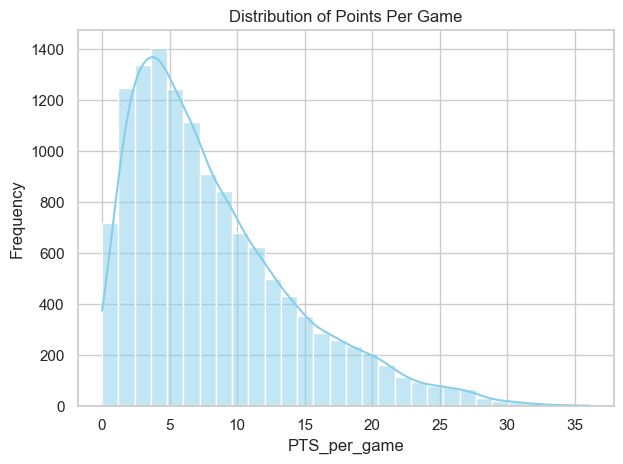

In [39]:
sns.set(style="whitegrid")

def plot_histogram(column, color, title):
    sns.histplot(df_team_player[column], kde=True, bins=30, color=color)
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

plot_histogram("PTS_per_game", "skyblue", "Distribution of Points Per Game")

### Distribution of Points Per Game

- The distribution is right-skewed, meaning most players score under 10 PPG, with fewer elite scorers reaching 20+.
- This reinforces the idea that high scorers are outliers — likely candidates for awards like MVP or All-NBA.
- It's a good candidate for feature scaling or log transformation if used in modeling.
---

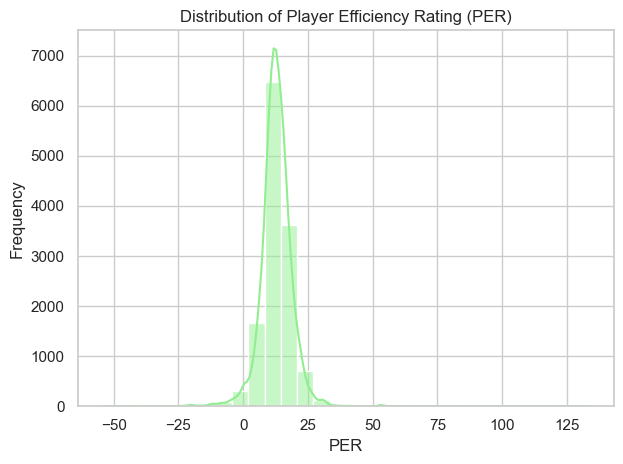

In [40]:
plot_histogram("PER", "lightgreen", "Distribution of Player Efficiency Rating (PER)")

### Distribution of Player Efficiency Rating (PER)

- PER is normally distributed, centered around 15, which is the league average by design.
- Outliers on the high end (25+) indicate superstar-level performance.
- Since PER incorporates many performance metrics, it's likely a strong driver for MVP and All-NBA predictions.
---

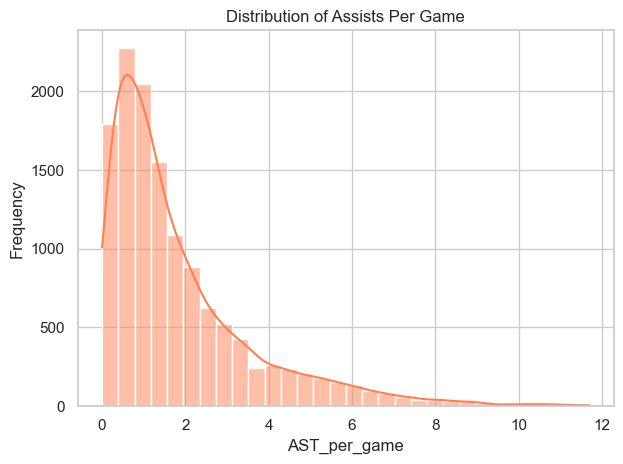

In [41]:
plot_histogram("AST_per_game", "coral", "Distribution of Assists Per Game")

### Distribution of Assists Per Game (AST_per_game)

- Right-skewed like PTS, indicating most players
average low assists, with only a few primary
ball-handlers reaching high numbers.
- High assist rates could be significant for MVP or
All-NBA guards (PGs/SGs), and should be evaluated
alongside position.

---


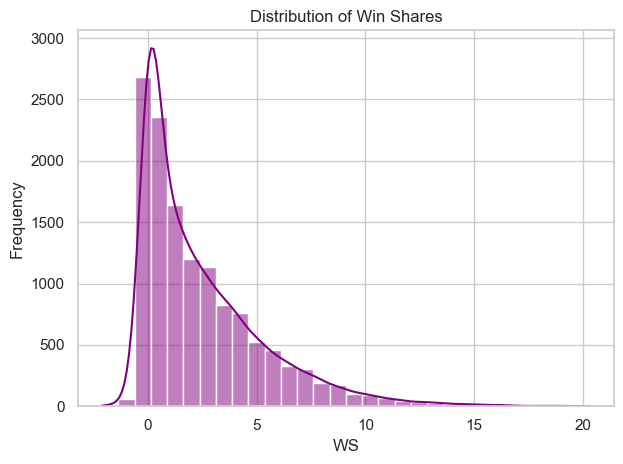

In [42]:
plot_histogram("WS", "purple", "Distribution of Win Shares")

### Distribution of Win Shares (WS)

- Strong right skew; most players contribute little to team
wins, while elite players post WS > 5 or 10.
- Since MVP and All-NBA are team-success-weighted
awards, WS is a very relevant feature.
- Consider it a top candidate for further modeling and
correlation testing.

---

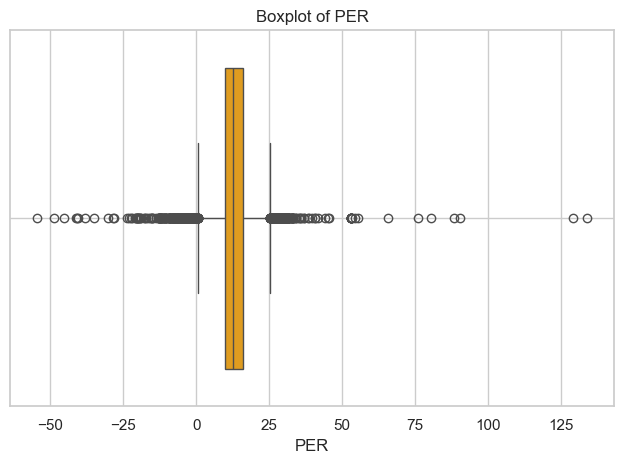

In [43]:
# ==== Boxplots for Outlier Detection ====
def plot_box(column, color):
    sns.boxplot(x=df_team_player[column], color=color)
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_box("PER", "orange")


### Boxplot of Player Efficiency Rating (PER)

- Highlights numerous high-end outliers, likely MVP
candidates.
- Reinforces earlier takeaway: PER is mostly normal,
but MVP/All-NBA players will reside in the far-right
tail.
---

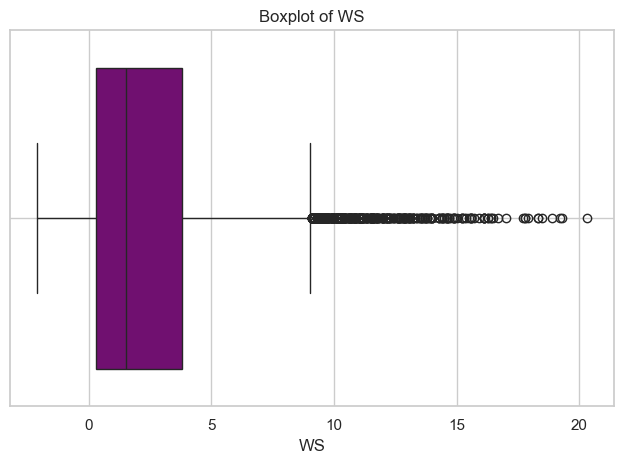

In [44]:
plot_box("WS", "purple")

### Boxplot of Win Shares (WS)

- Strong right skew again.
- High outlier WS values reinforce how few players truly
drive wins — valuable signal for MVP selection.

---

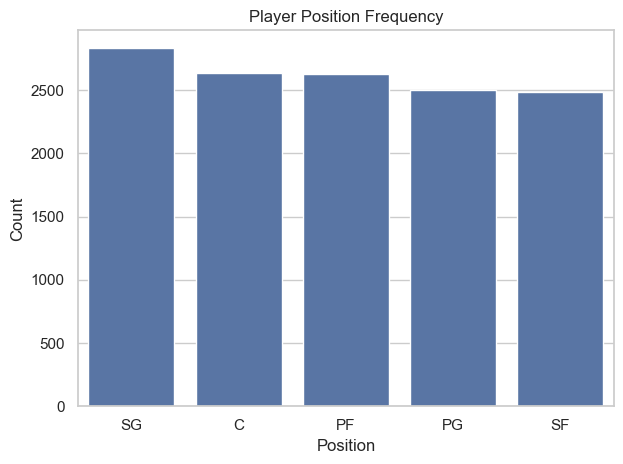

In [45]:
# ==== Categorical Variable: Position ====
sns.countplot(x="Pos", data=df_team_player, order=df_team_player["Pos"].value_counts().index)
plt.title("Player Position Frequency")
plt.xlabel("Position")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Player Position Frequency

- Fairly even distribution across positions,
but Shooting Guards (SG) are slightly
more frequent.
---

##  2. Bivariate and Multivariate Analysis

This section explores how key numeric and categorical variables relate to one another and to award selections.

###  Correlation Heatmap

The correlation matrix reveals the relationships between performance metrics and award flags:
- **PTS_per_game and WS**: Strong positive correlation (0.76), suggesting that high scorers contribute significantly to team wins.
- **PER** is moderately correlated with PTS, AST, and WS, showing it captures multiple performance dimensions.
- Awards like **MVP**, **All_NBA**, and **DEF_Team** show weaker correlations with raw stats, implying other selection factors.

###  PER vs PTS_per_game Scatter Plot

- Players with higher **PTS_per_game** generally have higher **PER**, with All-NBA selections clustering in the top-right.
- Color gradient (hue) shows players on 1st, 2nd, and 3rd All-NBA teams typically fall into the high-efficiency and high-scoring quadrant.

###  Average PER by All-NBA Selection

- Clear trend: average **PER** decreases as the All-NBA team level drops (1st > 2nd > 3rd).
- Non-selected players have significantly lower PERs on average.

###  Crosstab: Position vs All-NBA Team

A positional breakdown of All-NBA selections:
- **PGs and PFs** have slightly higher representation on All-NBA teams.
- C, SG, and SF show balanced but slightly lower selection counts.
- Useful for identifying positional biases in award recognition.
---

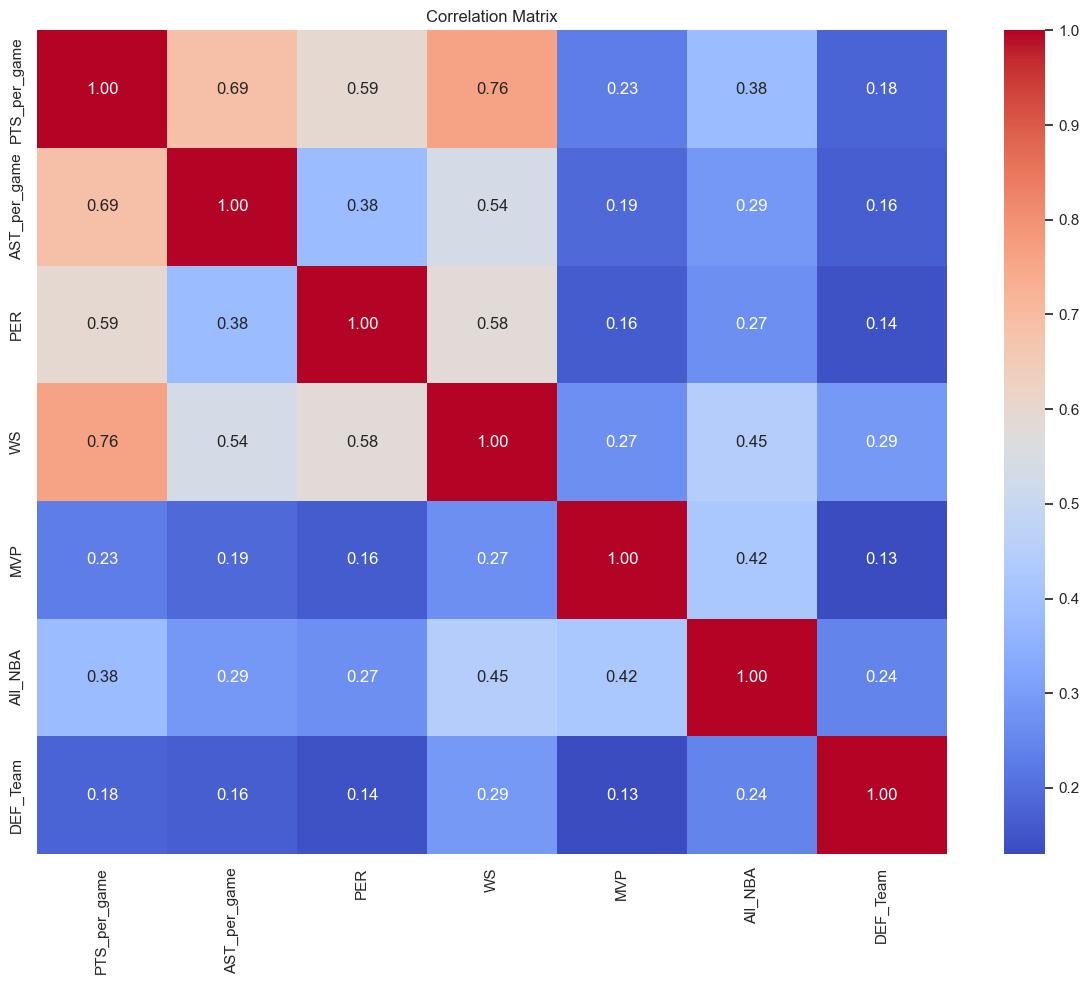

In [48]:
# Correlation Heatmap
plt.figure(figsize=(12, 10))
selected_cols = ['PTS_per_game', 'AST_per_game', 'PER', 'WS', 'MVP', 'All_NBA', 'DEF_Team']
sns.heatmap(df_team_player[selected_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

### Correlation Matrix Heatmap
Strongest correlations:
- PTS_per_game and WS (0.76): Suggests players who score more tend to contribute
significantly to team wins.

- PTS_per_game and AST_per_game (0.69): Indicates scorers often assist more, or that
high-usage players do both.

- WS and PER (0.58): Players who are more efficient tend to also contribute more wins

Awards correlations:
- WS has the strongest correlation with All-NBA selection (0.45), more than PTS or PER.

- All_NBA correlates more with MVP (0.42) than with DEF_Team (0.24), which aligns with
expectations.

- DEF_Team has generally low correlations with scoring or PER, hinting that selections
are based more on defensive metrics not captured here.
---

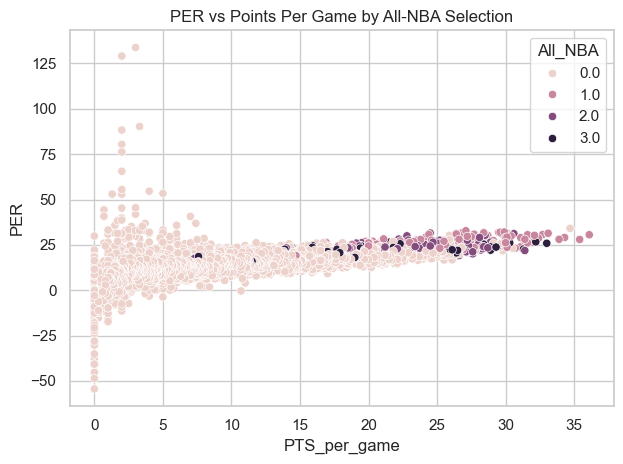

In [49]:
# Scatter Plot: Points vs PER with All-NBA hue
sns.scatterplot(data=df_team_player, x='PTS_per_game', y='PER', hue='All_NBA')
plt.title("PER vs Points Per Game by All-NBA Selection")
plt.tight_layout()
plt.show()

### Scatter Plot: All-NBA Selections by Points and Efficiency
Clear clustering by All-NBA level:
- Higher All-NBA tiers (1.0, 2.0, 3.0) are in the upper-right: more points and higher PER.
- Non-selected players (0.0) mostly fall in the low PTS and low PER range.

This supports that both scoring and efficiency are important predictors for making All-NBA teams.

---

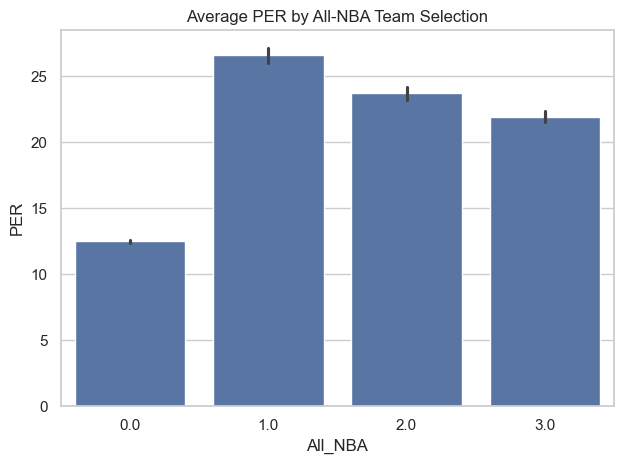

In [50]:
# Average PER by All-NBA Selection
sns.barplot(data=df_team_player, x='All_NBA', y='PER')
plt.title("Average PER by All-NBA Team Selection")
plt.tight_layout()
plt.show()

### Bar Plot: Average PER by All-NBA Team Selection

PER declines from All-NBA 1st to 3rd team:
- 1st Team: ~26+
- 2nd Team: ~24
- 3rd Team: ~22

-Non-selected players average around PER ~12,
showing a clear statistical gap.

-This validates PER as a key feature for
modeling All-NBA selections.

---

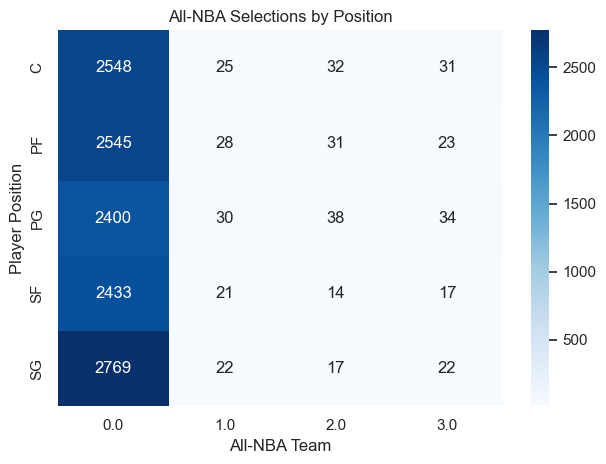

In [53]:
# Crosstab: Position vs All-NBA
sns.heatmap(crosstab, annot=True, fmt="d", cmap="Blues")
plt.title("All-NBA Selections by Position")
plt.xlabel("All-NBA Team")
plt.ylabel("Player Position")
plt.tight_layout()
plt.show()

### Crosstab: Position vs. All-NBA

-PGs and PFs dominate All-NBA selection:
- PG has highest total (102), followed by PF
(91), despite similar total counts across
positions.

- SFs have the fewest selections overall,
even though they have similar
representation.

-This could indicate positional biases or stronger
player pools at guard and forward spots during this period.



---

##  3. Missing Data Analysis

Understanding missing data is essential for building robust models and ensuring data quality.

###  Missing Values by Column

The horizontal bar chart shows:
- A few features like `Birth_State`, `Birth_City`, `Height`, and `Weight` have thousands of missing values.
- These are likely demographic or bio-measure fields that may not be essential for modeling performance or awards.
- Core performance metrics (like `PER`, `PTS_per_game`, `WS`, etc.) have **very few or no missing values**, which is ideal for predictive modeling.

###  Implications

- Features with high missingness (e.g., hand measurements, vertical leap) may be **excluded** from modeling unless you have a compelling reason to impute them.
- Low-missing columns can be cleaned using mean/median imputation or row filtering if needed.


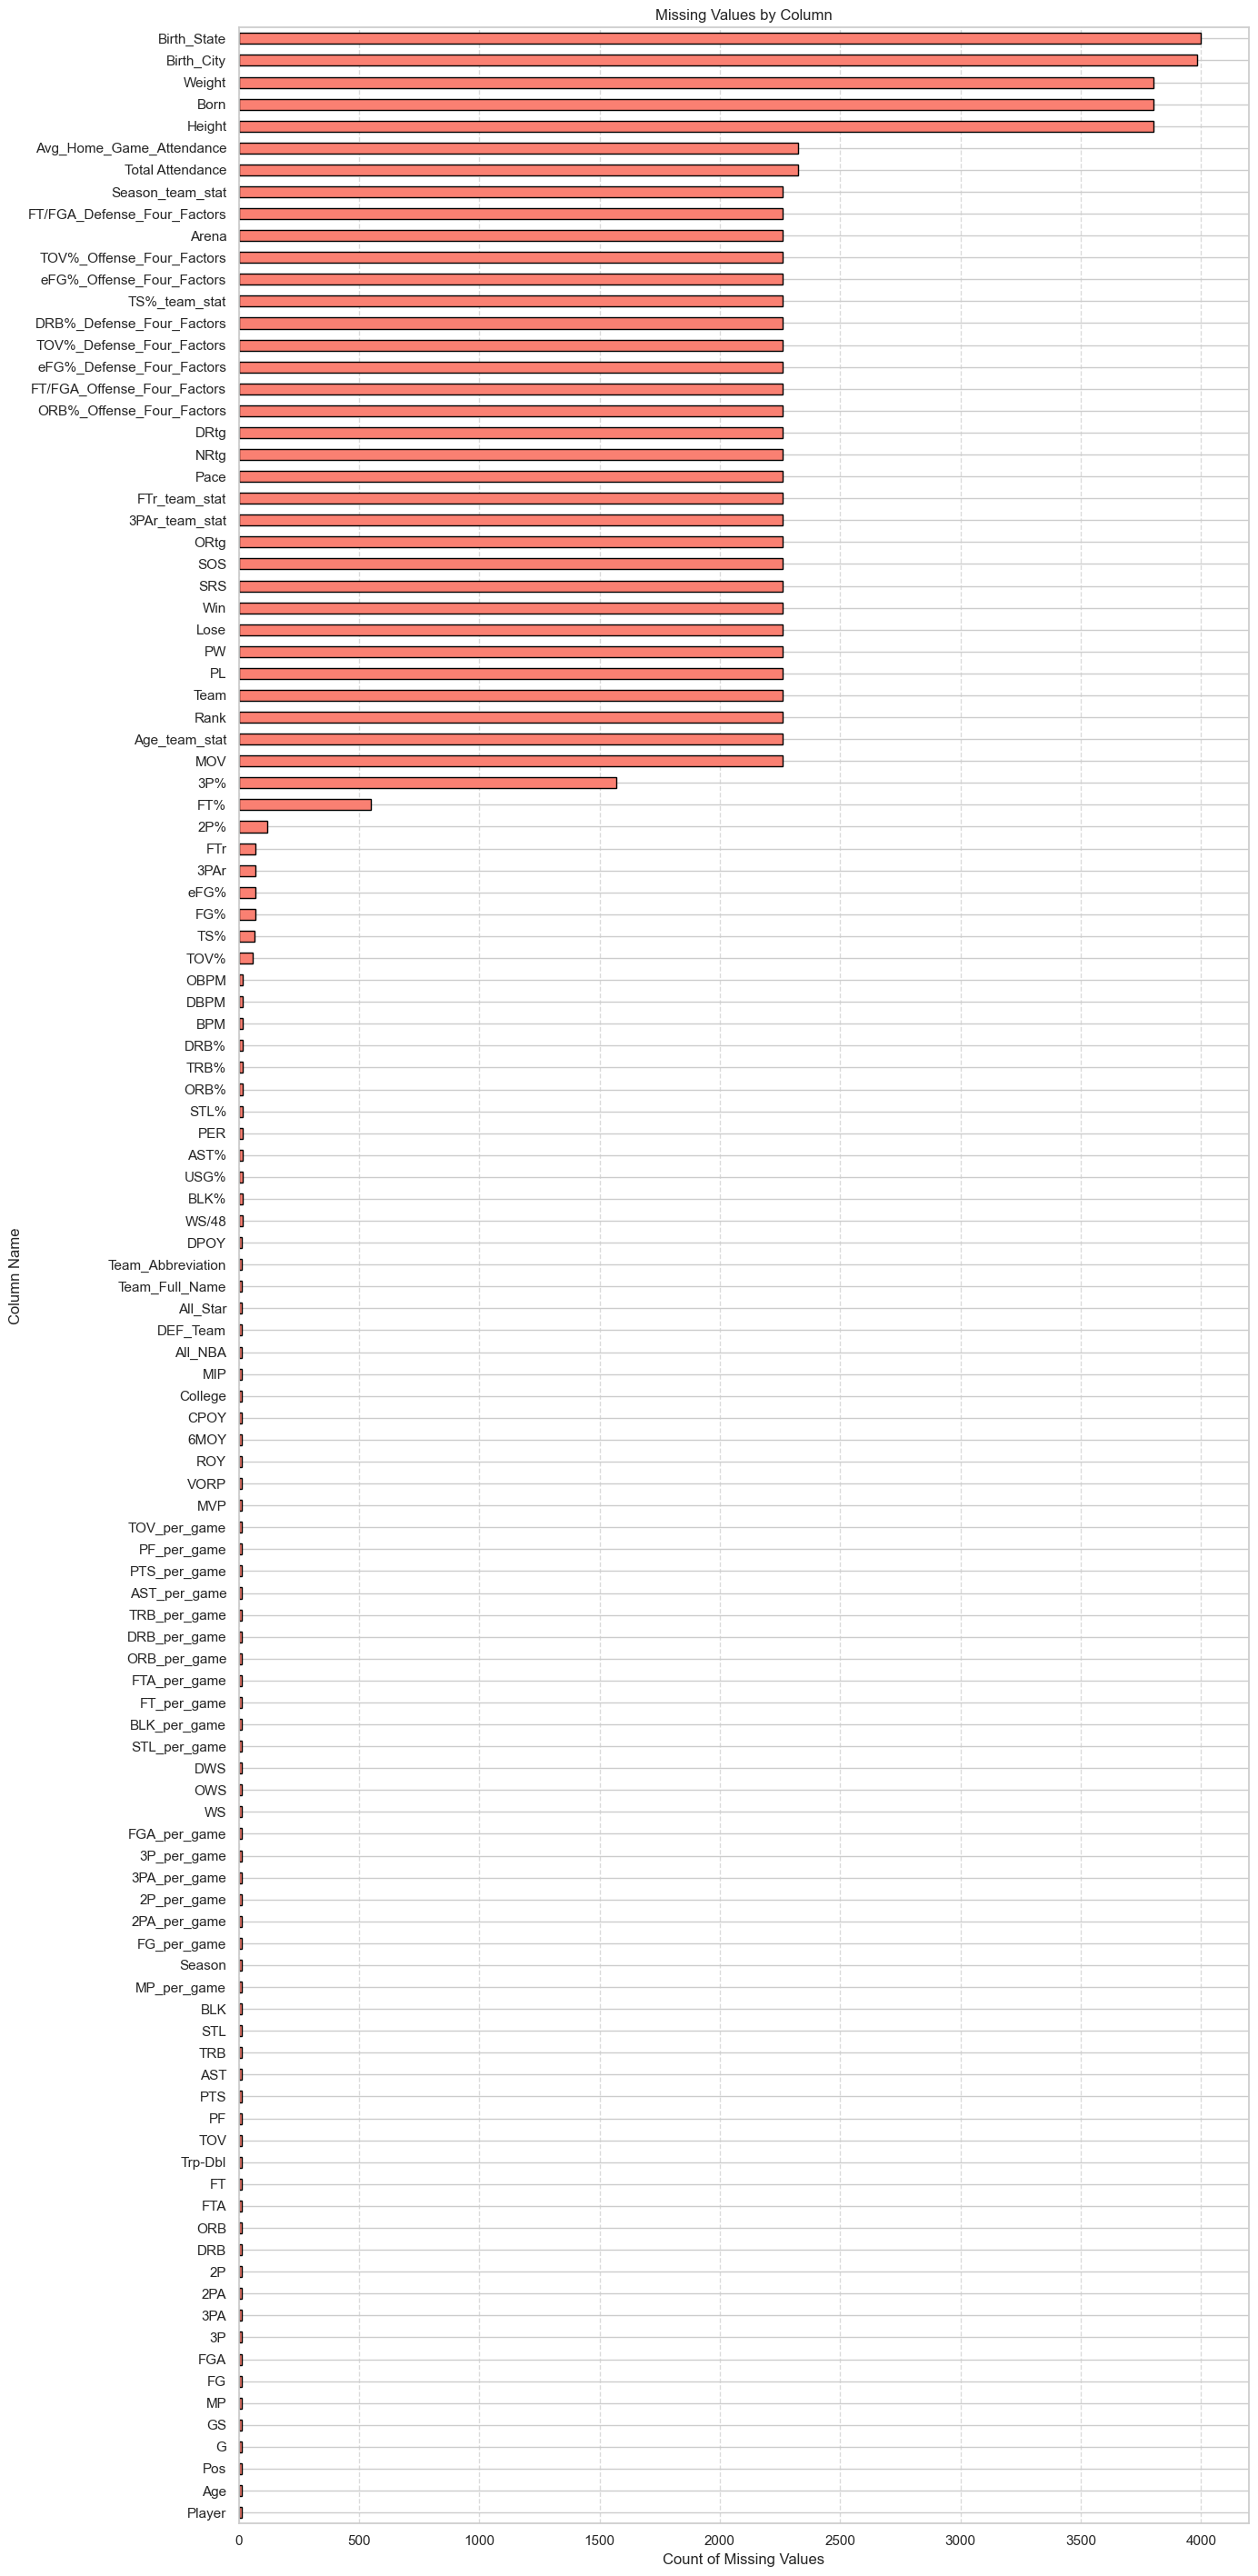

In [52]:
# ==== Missing Data Visualization  ====

# Calculate missing values
missing_data = df_team_player.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(ascending=True)

# Set up dynamic height for readability
plt.figure(figsize=(14, 0.25 * len(missing_data)))

# Plot
missing_data.plot(kind='barh', color='salmon', edgecolor='black')
plt.title("Missing Values by Column")
plt.xlabel("Count of Missing Values")
plt.ylabel("Column Name")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


##  Key Insights from the Missing Values Bar Chart

### 1.  Columns with Extreme Missingness (Over 3,500 Rows)
- `Birth_State`, `Weight`, `Height`, `Birth_City`, and `Born` all have nearly **4,000 missing values**.
- That’s roughly **30% of the total dataset** (~13,000+ rows), making them poor candidates for modeling unless they're essential.

**Action:**  
- Consider **dropping** these columns unless you plan to do **demographic analysis**.
- Alternatively, **impute** from external sources like the **NBA API** or **Wikipedia**.

---

### 2.  Moderate Missingness (1,800–2,200 Rows Missing)
Primarily **team and attendance-related metrics**:
- `Avg_Home_Game_Attendance`
- `Total Attendance`
- `FT/FGA_Defense_Four_Factors`, `TOV%_Defense_Four_Factors`, etc.

**Action:**  
- These may be missing for players not associated with games (e.g., trades, DNPs, inactive status).
- Either **drop** or **impute using team-level aggregates** if you intend to use them in modeling.

---

### 3.  Sporadic Missingness (Under 100 Rows)
Examples:
- `VORP`, `WS`, `OWS`, `DWS`, `eFG%`, `3PA_team`, etc.

**Action:**  
- These are **safe to impute** using **median, mean, or mode**.
- Alternatively, drop the rows if you're modeling and still retain thousands of complete records.

---

### 4.  Most Core Performance Stats Are Fully Complete
- Features like `PTS_per_game`, `PER`, `AST_per_game`, `WS`, etc., have **no missing values**.

**Insight:**  
These are **ideal predictors** for statistical modeling.


##  4. Conclusion: Summary of EDA Findings

This exploratory data analysis (EDA) of NBA team and player data from the **2020 to 2025 seasons** provides a strong statistical foundation for modeling individual accolades such as **MVP**, **All-NBA**, and **All-Defensive Team** selections.

###  Key Takeaways

- **Data Structure & Quality**  
  The dataset includes over **13,000 player-season records** with comprehensive individual, team, and award-related statistics.  
  - Core performance metrics (`PTS_per_game`, `PER`, `WS`) are fully populated and ready for modeling.  
  - Most missing values are in **demographics and attendance features**, which can be dropped or selectively imputed.

- **Performance Distributions**  
  Key metrics such as `PTS_per_game`, `PER`, and `WS` exhibit **right-skewed distributions with high-end outliers**.  
  - These outliers often represent award-caliber players and are important for predictive modeling.

- **Positional and Team Insights**  
  - **Shooting Guards (SGs)** are the most common position.  
  - **Point Guards (PGs)** and **Power Forwards (PFs)** dominate **All-NBA** selections.  
  - Around **61% of players were on playoff teams**, indicating a possible connection between playoff presence and award recognition.

- **Multivariate Patterns**  
  - Strong positive correlations exist between `PTS_per_game`, `PER`, and `WS`.  
  - **All-NBA selections cluster** in the upper-right quadrant of PER vs PTS, confirming that efficiency and scoring matter.  
  - Average PER clearly declines from 1st to 3rd team.

- **Outliers as Signals**  
  - High outliers in `PER` and `WS` are not discarded; they often **signal elite players** and help distinguish stars from role players.

---

### Final Note

This EDA confirms that the dataset is **rich, reliable, and aligned with award trends**. These findings enable the next steps:  
- **Feature engineering**  
- **Classification modeling**  
To build predictive tools for award forecasting.
